# Customer Churn Prediction


## 1. Présentation du projet

### Objectif

L'objectif de ce projet est de développer un modèle de Machine Learning capable
de prédire si un client est susceptible de quitter (`Churn`) une entreprise de
télécommunications.

La prédiction du churn est un problème de classification binaire :

- `No` → le client reste ;
- `Yes` → le client quitte l'entreprise.

L'objectif n'est pas seulement d'obtenir une bonne Accuracy, mais surtout de
détecter efficacement les clients susceptibles de churner. Le **Recall** et le
**F1-score** de la classe `Yes` seront donc particulièrement importants.

### Données

Le dataset contient des informations sur les clients, notamment :

- informations démographiques ;
- ancienneté (`tenure`) ;
- services souscrits ;
- type de contrat ;
- méthode de paiement ;
- frais mensuels et totaux.

La variable cible est `Churn`.

### Approche

Le projet suit un workflow complet de Machine Learning :

1. Compréhension et nettoyage des données ;
2. Analyse exploratoire des données (EDA) ;
3. Préparation des variables ;
4. Séparation Train / Test ;
5. Prétraitement avec `ColumnTransformer` et `Pipeline` ;
6. Construction d'une baseline ;
7. Entraînement et optimisation de plusieurs modèles ;
8. Comparaison des modèles par validation croisée ;
9. Sélection et interprétation du modèle final ;
10. Optimisation du seuil de décision sur les données d'entraînement ;
11. Évaluation finale sur le jeu de test ;
12. Sauvegarde et rechargement du modèle ;
13. Prédiction sur un nouveau client.

### Perspective métier

Un modèle de churn peut aider une entreprise à identifier les clients
présentant un risque élevé de départ afin de mettre en place des actions de
rétention ciblées.

## 2. Chargement et compréhension des données

### 2.1 Importation des bibliothèques

In [1]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict , GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier , GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    make_scorer,
    roc_auc_score, 
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

### 2.2 Chargement et compréhension des données

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [3]:
print("Dimensions du dataset :", df.shape)

Dimensions du dataset : (7043, 21)


In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


## 3. Nettoyage des données

Cette étape consiste à identifier et corriger les problèmes pouvant affecter
l'analyse et l'entraînement des modèles.

Nous vérifions notamment :

- les valeurs manquantes ;
- les types de données ;
- les doublons ;
- les identifiants uniques ;
- les valeurs incohérentes.

In [7]:
print("Valeurs manquantes par variable :")
df.isnull().sum()

Valeurs manquantes par variable :


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
df["TotalCharges"].str.strip().eq("").sum()

np.int64(11)

La variable `TotalCharges` représente une valeur numérique, mais elle est
stockée au format `object`. Une inspection de ses valeurs montre la présence
d'espaces dans 11 observations.

Ces valeurs doivent être traitées avant de convertir la variable en type
numérique.

In [9]:
df.loc[df["TotalCharges"].str.strip() == "", ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [10]:
df["TotalCharges"] = df["TotalCharges"].replace(" ", "0")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"])

In [11]:
print("Type de TotalCharges :", df["TotalCharges"].dtype)
print("Valeurs manquantes :", df["TotalCharges"].isnull().sum())

Type de TotalCharges : float64
Valeurs manquantes : 0


Après avoir examiné les observations concernées, nous constatons que les **11 clients ont une ancienneté (`tenure`) de 0 mois**. Cela indique qu'il s'agit de nouveaux clients qui viennent de souscrire au service et qui n'ont donc pas encore accumulé de frais.

Ainsi, ces valeurs vides semblent être cohérentes avec le contexte des données plutôt que de correspondre à une erreur de saisie.

Afin de conserver ces observations et de pouvoir utiliser `TotalCharges` comme variable numérique, les valeurs vides sont remplacées par `0`. La colonne est ensuite convertie en type numérique.


In [12]:
# Vérification des doublons
print("Lignes dupliquées :", df.duplicated().sum())
print("CustomerID dupliqués :", df["customerID"].duplicated().sum())

Lignes dupliquées : 0
CustomerID dupliqués : 0


### Conclusion

Après les différentes vérifications, les données ne présentent pas de doublons ni de valeurs manquantes non traitées. La variable `TotalCharges` a été nettoyée et convertie en format numérique après investigation des 11 valeurs vides.

Les données sont désormais suffisamment propres et cohérentes pour passer à l'étape suivante : **l'analyse exploratoire des données (EDA)**.


## 4. Analyse exploratoire des données (EDA)

L'objectif de cette étape est de comprendre la distribution des données et
d'identifier les variables pouvant être associées au churn des clients.

Nous commençons par analyser la variable cible `Churn`, puis nous étudions
les variables numériques et catégorielles.

### 4.1 Distribution de la variable cible

Nombre de clients par classe :
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Pourcentage de clients par classe :
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


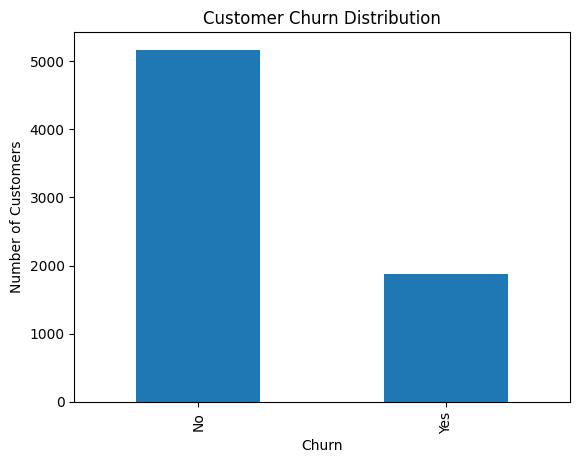

In [13]:
print("Nombre de clients par classe :")
print(df["Churn"].value_counts())

print("\nPourcentage de clients par classe :")
print(df["Churn"].value_counts(normalize=True) * 100)
df["Churn"].value_counts().plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

Environ 26,5 % des clients ont quitté l'entreprise contre 73,5 % qui sont restés. La variable cible est donc déséquilibrée, ce qui devra être pris en compte lors de l'évaluation des modèles. L'Accuracy seule ne sera pas suffisante pour mesurer leurs performances.

### 4.2 Analyse des variables numériques

In [14]:
df["tenure"].describe()

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

In [15]:
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"]
)

In [16]:
sns.set_theme(style="whitegrid")

def plot_churn_proportion(df, column, title):
    """
    Affiche un graphique à barres empilées 100% pour visualiser 
    la proportion de Churn par catégorie.
    """
    # Création du tableau croisé dynamique en pourcentage
    crosstab = pd.crosstab(df[column], df["Churn"], normalize="index") * 100
    
    # Création du graphique
    ax = crosstab.plot(kind="bar", stacked=True, figsize=(8, 5), color=["#1f77b4", "#d62728"])
    
    plt.title(title, fontsize=14, pad=15)
    plt.xlabel(column, fontsize=12)
    plt.ylabel("Proportion (%)", fontsize=12)
    plt.legend(title="Churn", bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.xticks(rotation=45, ha="right")
    
    # Ajout des annotations (pourcentages) au centre des barres
    for p in ax.patches:
        width, height = p.get_width(), p.get_height()
        x, y = p.get_xy()
        if height > 5: # N'afficher que si la zone est assez grande
            ax.text(x + width/2, 
                    y + height/2, 
                    f'{height:.1f}%', 
                    ha='center', 
                    va='center', 
                    color='white', 
                    fontweight='bold')
            
    plt.tight_layout()
    plt.show()

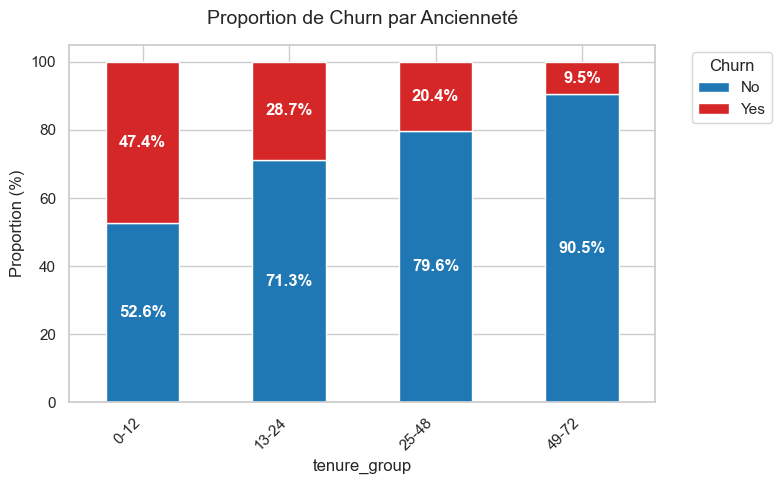

In [17]:
plot_churn_proportion(df, "tenure_group", "Proportion de Churn par Ancienneté")

L'ancienneté semble être associée au churn. Les clients ayant une faible ancienneté présentent une proportion de churn plus élevée que les clients ayant une ancienneté plus importante. Cette tendance suggère que les premières périodes de la relation client constituent une phase particulièrement sensible au risque de départ.


In [18]:
df["MonthlyCharges"].describe()

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64

In [19]:
print(df.groupby("Churn")["MonthlyCharges"].agg(["mean", "median"]))

            mean  median
Churn                   
No     61.265124  64.425
Yes    74.441332  79.650


Les clients ayant quitté l'entreprise présentent des charges mensuelles globalement plus élevées que les clients restés. Cette différence suggère une association entre le niveau des charges mensuelles et le risque de churn. Cette variable pourra donc être pertinente pour la modélisation.

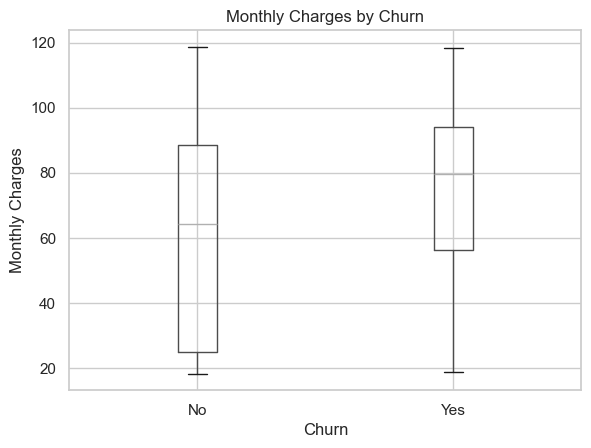

In [20]:
df.boxplot(
    column="MonthlyCharges",
    by="Churn"
)

plt.title("Monthly Charges by Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

In [21]:
print(df.groupby("Churn")["TotalCharges"].mean())
print(df.groupby("Churn")["TotalCharges"].median())

Churn
No     2549.911442
Yes    1531.796094
Name: TotalCharges, dtype: float64
Churn
No     1679.525
Yes     703.550
Name: TotalCharges, dtype: float64


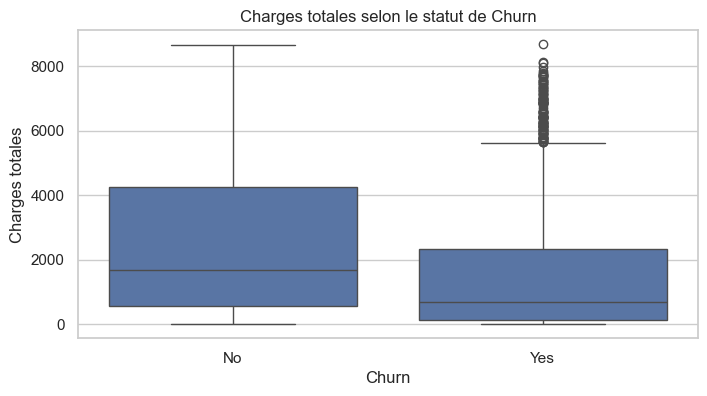

In [22]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="Churn", y="TotalCharges")
plt.title("Charges totales selon le statut de Churn")
plt.xlabel("Churn")
plt.ylabel("Charges totales")
plt.show()

### 4.3 Analyse du churn selon les variables catégorielles

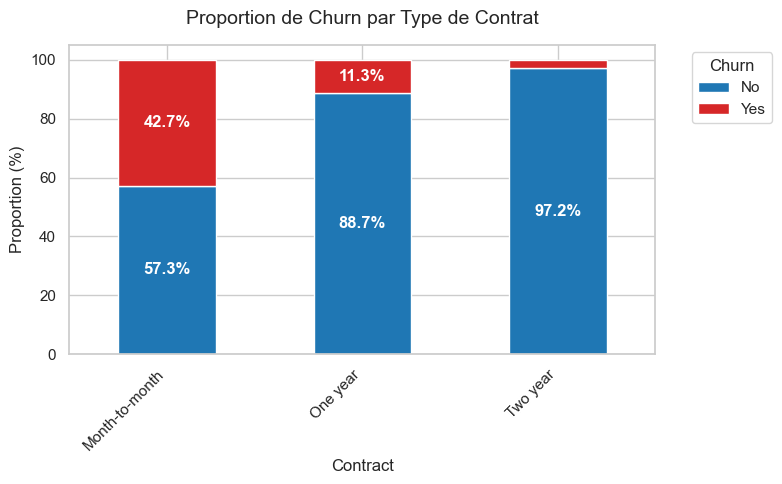

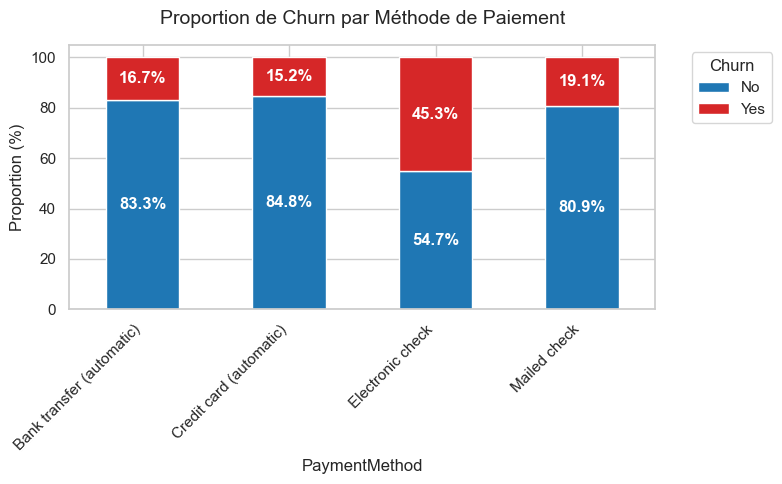

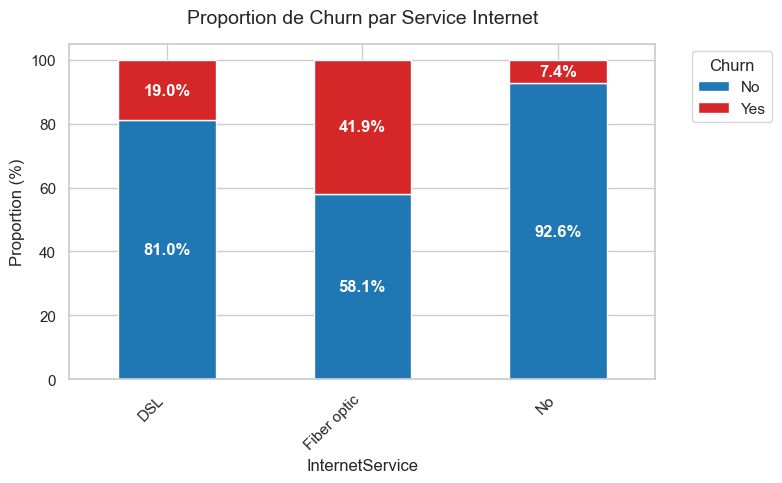

In [23]:
plot_churn_proportion(df, "Contract", "Proportion de Churn par Type de Contrat")

plot_churn_proportion(df, "PaymentMethod", "Proportion de Churn par Méthode de Paiement")

plot_churn_proportion(df, "InternetService", "Proportion de Churn par Service Internet")

Les variables catégorielles présentent des différences importantes de taux de churn. Le churn est particulièrement élevé chez les clients ayant un contrat mensuel (42,7 %), utilisant l’Electronic check (45,3 %) ou la fibre optique (41,9 %). À l’inverse, les contrats de longue durée et les autres catégories présentent des taux de churn plus faibles.

Ces résultats mettent en évidence des associations entre les caractéristiques contractuelles et de service et le churn, sans pour autant établir de relation causale.


In [24]:
df.drop(columns=["tenure_group"], inplace=True)

## 5. Préparation des données pour le Machine Learning

In [25]:
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

`customerID` est un identifiant unique et ne contient pas d'information comportementale exploitable pour prédire le churn. Il est donc exclu des variables utilisées pour l'apprentissage.

In [26]:
print("X :", X.shape)
print("y :", y.shape)

X : (7043, 19)
y : (7043,)


In [27]:
print("\nTypes des variables :")
X.dtypes


Types des variables :


gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
dtype: object

## 6. Séparation des données

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [29]:
print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : (5634, 19)
X_test  : (1409, 19)
y_train : (5634,)
y_test  : (1409,)


Les données sont séparées en un ensemble d'entraînement (80 %) et un ensemble de test (20 %). L'option `stratify=y` permet de conserver une proportion similaire de clients ayant churné et n'ayant pas churné dans les deux ensembles.

In [30]:
print("\nRépartition de Churn dans train :")
print(y_train.value_counts(normalize=True) * 100)

print("\nRépartition de Churn dans test :")
print(y_test.value_counts(normalize=True) * 100)


Répartition de Churn dans train :
Churn
No     73.464679
Yes    26.535321
Name: proportion, dtype: float64

Répartition de Churn dans test :
Churn
No     73.456352
Yes    26.543648
Name: proportion, dtype: float64


## 7. Prétraitement des variables

In [31]:
numeric_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

In [32]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

- Les variables numériques sont standardisées avec `StandardScaler`.
- Les variables catégorielles sont encodées en variables binaires avec `OneHotEncoder`.
- Le prétraitement est intégré aux pipelines afin d'éviter les fuites de données
pendant la validation croisée.

## 8. Modèle de référence — DummyClassifier

Avant d'entraîner des modèles complexes, un modèle très simple est utilisé comme référence.

Le DummyClassifier prédit systématiquement la classe majoritaire.

In [35]:
f1_scorer = make_scorer(
    f1_score,
    pos_label="Yes"
)

In [36]:
baseline = DummyClassifier(strategy="most_frequent")

baseline_accuracy = cross_val_score(
    baseline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

In [37]:
baseline_f1 = cross_val_score(
    baseline,
    X_train,
    y_train,
    cv=5,
    scoring=f1_scorer
)

In [38]:
print("Baseline Accuracy CV :", baseline_accuracy.mean())
print("Baseline F1 CV :", baseline_f1.mean())

Baseline Accuracy CV : 0.7346467539058252
Baseline F1 CV : 0.0


Le `DummyClassifier` sert de référence minimale pour vérifier que les modèles entraînés apportent une réelle amélioration dans la détection du churn.

## 9. Modélisation

On va tester plusieurs algorithmes de classification afin de comparer leurs performances.
Le F1-score de la classe `Yes` est utilisé comme métrique principale.

### 9.1 Decision Tree

In [ ]:
tree_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", DecisionTreeClassifier(
        random_state=42
    ))
])

tree_param_grid = {
    "model__max_depth": [3, 4, 5, 6, 7, 8, 10]
}

In [ ]:
tree_grid_search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=tree_param_grid,
    cv=5,
    scoring=f1_scorer,
    n_jobs=-1
)

tree_grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessing',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['SeniorCitizen',
                                                                          'tenure',
                                                                          'MonthlyCharges',
                                                                          'TotalCharges']),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         ['gender',
                                                                          'Partner',
                                                                          'Dependents',
                                                                          'PhoneService',
                                                                          'MultipleLines',
                                                                          'InternetService',
                                                                          'OnlineSecurity',
                                                                          'OnlineBackup',
                                                                          'DeviceProtection',
                                                                          'TechSupport',
                                                                          'StreamingTV',
                                                                          'StreamingMovies',
                                                                          'Contract',
                                                                          'PaperlessBilling',
                                                                          'PaymentMethod'])])),
                                       ('model',
                                        DecisionTreeClassifier(random_state=42))]),
             n_jobs=-1, param_grid={'model__max_depth': [3, 4, 5, 6, 7, 8, 10]},
             scoring=make_scorer(f1_score, response_method='predict', pos_label=Yes))

In [ ]:
print("Meilleurs paramètres :", tree_grid_search.best_params_)
print("Meilleur F1 CV :", tree_grid_search.best_score_)

best_tree = tree_grid_search.best_estimator_

Meilleurs paramètres : {'model__max_depth': 8}
Meilleur F1 CV : 0.562603316495099


### 9.2 RandomForestClassifier

In [ ]:
rf_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 8, 12],
    "model__min_samples_leaf": [1, 2, 5]
}

In [ ]:
rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=5,
    scoring=f1_scorer,
    n_jobs=-1
)

rf_grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessing',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['SeniorCitizen',
                                                                          'tenure',
                                                                          'MonthlyCharges',
                                                                          'TotalCharges']),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         ['gender',
                                                                          'Partner',
                                                                          'Dependents',
                                                                          'PhoneService',
                                                                          'MultipleLines',
                                                                          'InternetService',
                                                                          'OnlineSecurity',
                                                                          'OnlineBackup',
                                                                          'DeviceProtection',
                                                                          'TechSupport',
                                                                          'StreamingTV',
                                                                          'StreamingMovies',
                                                                          'Contract',
                                                                          'PaperlessBilling',
                                                                          'PaymentMethod'])])),
                                       ('model',
                                        RandomForestClassifier(n_jobs=-1,
                                                               random_state=42))]),
             n_jobs=-1,
             param_grid={'model__max_depth': [5, 8, 12],
                         'model__min_samples_leaf': [1, 2, 5],
                         'model__n_estimators': [100, 200]},
             scoring=make_scorer(f1_score, response_method='predict', pos_label=Yes))

In [ ]:
print("Meilleurs paramètres :", rf_grid_search.best_params_)
print("Meilleur F1 moyen :", rf_grid_search.best_score_)
best_rf = rf_grid_search.best_estimator_

Meilleurs paramètres : {'model__max_depth': 8, 'model__min_samples_leaf': 2, 'model__n_estimators': 100}
Meilleur F1 moyen : 0.578109617153509


### 9.3 GradientBoostingClassifier

In [ ]:
gb_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", GradientBoostingClassifier(
        random_state=42
    ))
])

In [ ]:
gb_param_grid = {
    "model__n_estimators": [100, 150],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3]
}

In [ ]:
gb_grid_search = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=gb_param_grid,
    cv=5,
    scoring=f1_scorer,
    n_jobs=-1
)

gb_grid_search.fit(X_train, y_train)

print("Meilleurs paramètres :", gb_grid_search.best_params_)
print("Meilleur F1 CV :", gb_grid_search.best_score_)
best_gb = gb_grid_search.best_estimator_

Meilleurs paramètres : {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100}
Meilleur F1 CV : 0.5906472401541496


### 9.4 SVM

In [ ]:
svm_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", SVC(
        kernel="rbf",
        random_state=42
    ))
])

In [ ]:
svm_param_grid = {
    "model__C": [0.1, 1, 10],
    "model__gamma": ["scale", 0.01, 0.1]
}

In [ ]:
svm_grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    cv=5,
    scoring=f1_scorer,
    n_jobs=-1
)

svm_grid_search.fit(X_train, y_train)

print("Meilleurs paramètres :", svm_grid_search.best_params_)
print("Meilleur F1 CV :", svm_grid_search.best_score_)
best_svm = svm_grid_search.best_estimator_

Meilleurs paramètres : {'model__C': 10, 'model__gamma': 'scale'}
Meilleur F1 CV : 0.5745030470025038


### 9.5 KNN

In [ ]:
knn_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", KNeighborsClassifier(
        n_neighbors=5
    ))
])

In [ ]:
knn_param_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21]
}

In [ ]:
knn_grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    cv=5,
    scoring=f1_scorer,
    n_jobs=-1
)

knn_grid_search.fit(X_train, y_train)

print("Meilleurs paramètres :", knn_grid_search.best_params_)
print("Meilleur F1 CV :", knn_grid_search.best_score_)
best_knn = knn_grid_search.best_estimator_


Meilleurs paramètres : {'model__n_neighbors': 21}
Meilleur F1 CV : 0.5984608817402599


### 9.6 MLP

In [ ]:
mlp_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", MLPClassifier(
        hidden_layer_sizes=(100,),
        max_iter=500,
        random_state=42
    ))
])

In [ ]:
mlp_param_grid = {
    "model__hidden_layer_sizes": [(50,), (100,), (100, 50)],
    "model__alpha": [0.0001, 0.001],
    "model__max_iter": [500, 1000]
}

In [ ]:
mlp_grid_search = GridSearchCV(
    estimator=mlp_pipeline,
    param_grid=mlp_param_grid,
    cv=5,
    scoring=f1_scorer,
    n_jobs=-1
)

mlp_grid_search.fit(X_train, y_train)

print("Meilleurs paramètres :", mlp_grid_search.best_params_)
print("Meilleur F1 CV :", mlp_grid_search.best_score_)
best_mlp = mlp_grid_search.best_estimator_

Meilleurs paramètres : {'model__alpha': 0.001, 'model__hidden_layer_sizes': (50,), 'model__max_iter': 1000}
Meilleur F1 CV : 0.5721130750641777


### 9.7 LogisticRegression

In [ ]:
logistic_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

logistic_param_grid = {
    "model__C": [0.01, 0.1, 1, 10]
}

logistic_grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_param_grid,
    cv=5,
    scoring=f1_scorer,
    n_jobs=-1
)

logistic_grid_search.fit(X_train, y_train)

print("Meilleurs paramètres :", logistic_grid_search.best_params_)
print("Meilleur F1 CV :", logistic_grid_search.best_score_)

best_logistic = logistic_grid_search.best_estimator_

Meilleurs paramètres : {'model__C': 10}
Meilleur F1 CV : 0.5989370800859029


## 10. Comparaison des modèles

In [ ]:
models = {
    "Logistic Regression": logistic_grid_search,
    "Decision Tree": tree_grid_search,
    "Random Forest": rf_grid_search,
    "Gradient Boosting": gb_grid_search,
    "SVM": svm_grid_search,
    "KNN": knn_grid_search,
    "MLP": mlp_grid_search
}

results_list = []

for name, grid in models.items():

    results_list.append({
        "Model": name,
        "F1_CV": grid.best_score_,
        "Best_Params": grid.best_params_
    })

results = pd.DataFrame(results_list)

results = results.sort_values(
    by="F1_CV",
    ascending=False
).reset_index(drop=True)

results

,Model,F1_CV,Best_Params
0,Logistic Regression,0.598937,{'model__C': 10}
1,KNN,0.598461,{'model__n_neighbors': 21}
2,Gradient Boosting,0.590647,"{'model__learning_rate': 0.1, 'model__max_dept..."
3,Random Forest,0.578110,"{'model__max_depth': 8, 'model__min_samples_le..."
4,SVM,0.574503,"{'model__C': 10, 'model__gamma': 'scale'}"
5,MLP,0.572113,"{'model__alpha': 0.001, 'model__hidden_layer_s..."
6,Decision Tree,0.562603,{'model__max_depth': 8}


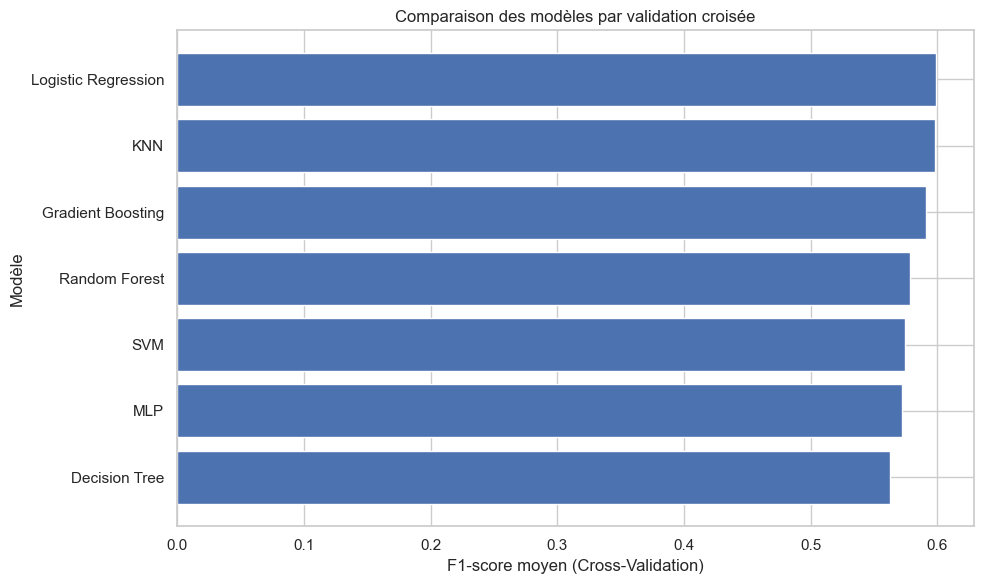

In [ ]:
# Trier les modèles selon leur F1-score en validation croisée
results_plot = results.sort_values("F1_CV", ascending=True)

plt.figure(figsize=(10, 6))

plt.barh(
    results_plot["Model"],
    results_plot["F1_CV"]
)

plt.xlabel("F1-score moyen (Cross-Validation)")
plt.ylabel("Modèle")
plt.title("Comparaison des modèles par validation croisée")

plt.tight_layout()
plt.show()

La ***Logistic Regression*** obtient le meilleur F1-score moyen en validation croisée
avec environ **0.599**, suivie de très près par KNN.

Elle est donc sélectionnée comme modèle final. Le jeu de test reste réservé
à l'évaluation finale du modèle sélectionné.

## 11. Analyse de la Logistic Regression
Après la comparaison des modèles par validation croisée, la Logistic Regression
est retenue comme modèle final.

Cette section vise à interpréter les variables les plus influentes dans les
prédictions du modèle.

### 11.1 Variables les plus influentes dans la Logistic Regression

La Logistic Regression permet d'analyser l'influence des variables sur la prédiction.

- Un coefficient positif est associé à une augmentation du risque de churn.
- Un coefficient négatif est associé à une diminution du risque de churn.

Cette analyse permet de mieux comprendre les décisions du modèle.

In [ ]:
# Récupérer le préprocesseur et le modèle
preprocessor_logistic = best_logistic.named_steps["preprocessing"]
model_logistic = best_logistic.named_steps["model"]

# Récupérer les noms des variables après le prétraitement
feature_names = preprocessor_logistic.get_feature_names_out()

# Récupérer les coefficients de la Logistic Regression
coefficients = model_logistic.coef_[0]

# Créer un DataFrame
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Nettoyer les noms des variables
coef_df["Feature"] = (
    coef_df["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

# Trier du coefficient le plus positif au plus négatif
coef_df = coef_df.sort_values(
    by="Coefficient",
    ascending=False
).reset_index(drop=True)

coef_df

,Feature,Coefficient
0,InternetService_Fiber optic,1.303760
1,TotalCharges,0.581244
2,Contract_Month-to-month,0.541465
3,StreamingMovies_Yes,0.519026
4,StreamingTV_Yes,0.518433
5,MultipleLines_Yes,0.333089
6,DeviceProtection_Yes,0.221848
7,PaymentMethod_Electronic check,0.166955
8,OnlineBackup_Yes,0.153010
9,OnlineSecurity_No,0.126948


Les coefficients montrent que `InternetService_Fiber optic` et
`Contract_Month-to-month` sont notamment associés à un risque de churn plus élevé.

À l'inverse, une ancienneté (`tenure`) élevée et un contrat de deux ans
(`Contract_Two year`) sont associés à un risque de churn plus faible.

Ces résultats sont cohérents avec plusieurs observations réalisées lors de l'EDA.
Ils représentent des associations apprises par le modèle et non des relations causales.

## 12. Optimisation du seuil de décision

Par défaut, une classification binaire basée sur `predict()` utilise un seuil de décision de 0.50.

Dans ce projet, nous étudions différents seuils afin d'observer le compromis entre Precision et Recall.

Les seuils sont sélectionnés à partir de prédictions out-of-fold sur les données d'entraînement afin de ne pas utiliser directement le jeu de test pour cette sélection.

In [ ]:
y_proba_oof = cross_val_predict(
    best_logistic,
    X_train,
    y_train,
    cv=5,
    method="predict_proba"
)[:, 1]

In [ ]:
threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.05):

    y_pred_threshold = np.where(
        y_proba_oof >= threshold,
        "Yes",
        "No"
    )

    precision = precision_score(
        y_train,
        y_pred_threshold,
        pos_label="Yes",
        zero_division=0
    )

    recall = recall_score(
        y_train,
        y_pred_threshold,
        pos_label="Yes",
        zero_division=0
    )

    f1 = f1_score(
        y_train,
        y_pred_threshold,
        pos_label="Yes",
        zero_division=0
    )

    threshold_results.append([
        threshold,
        precision,
        recall,
        f1
    ])


In [ ]:
threshold_df = pd.DataFrame(
    threshold_results,
    columns=["Threshold", "Precision", "Recall", "F1"]
)

threshold_df

,Threshold,Precision,Recall,F1
0,0.10,0.397840,0.936455,0.558436
1,0.15,0.440930,0.913712,0.594818
2,0.20,0.475440,0.867559,0.614255
3,0.25,0.508787,0.813378,0.625997
4,0.30,0.538064,0.765886,0.632073
5,0.35,0.568827,0.710368,0.631767
6,0.40,0.596608,0.658863,0.626192
7,0.45,0.629938,0.608027,0.618788
8,0.50,0.658380,0.549164,0.598833
9,0.55,0.688910,0.490301,0.572880


In [ ]:
best_threshold_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

best_threshold = best_threshold_row["Threshold"]

print("Meilleur seuil :", best_threshold)
print("Meilleur F1 OOF :", best_threshold_row["F1"])

Meilleur seuil : 0.30000000000000004
Meilleur F1 OOF : 0.6320728677891251


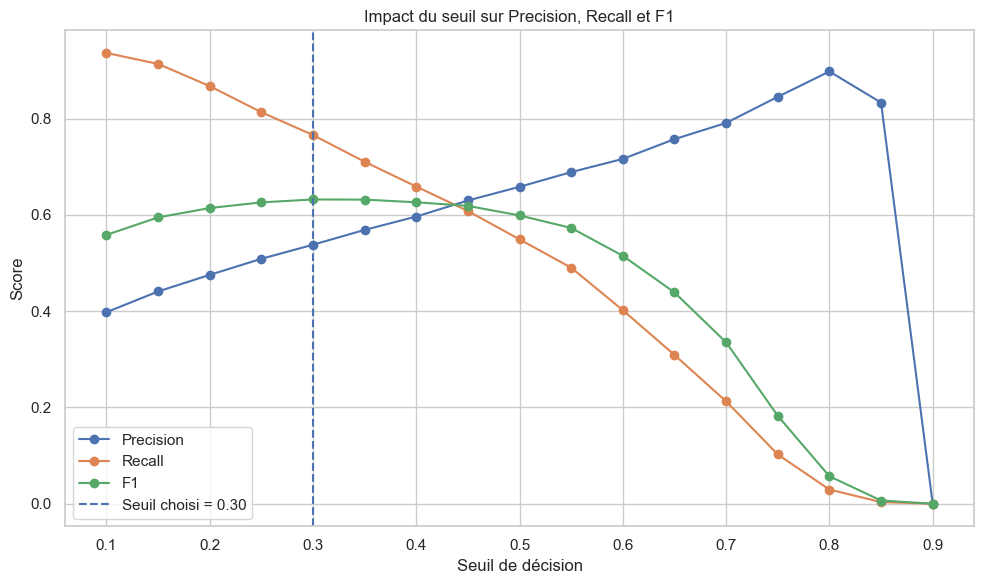

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1"
)

plt.axvline(
    x=best_threshold,
    linestyle="--",
    label=f"Seuil choisi = {best_threshold:.2f}"
)

plt.xlabel("Seuil de décision")
plt.ylabel("Score")
plt.title("Impact du seuil sur Precision, Recall et F1")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

### Justification métier du seuil

Dans un problème de churn, ne pas détecter un client qui risque de partir
peut être plus coûteux que contacter un client qui finalement reste.

Le seuil de **0.30** permet d'augmenter le Recall et donc d'identifier
davantage de clients à risque.

Ce choix accepte une baisse de Precision en échange d'une meilleure détection
des churners, ce qui peut permettre à l'entreprise de mettre en place des
actions de rétention plus tôt.

## 13. Évaluation finale

### 13.1 Prédiction avec le seuil optimisé

In [ ]:
y_proba_test = best_logistic.predict_proba(X_test)[:, 1]

# Seuil optimisé
threshold = best_threshold

y_pred_final = np.where(
    y_proba_test >= threshold,
    "Yes",
    "No"
)

print("Seuil utilisé :", threshold)

Seuil utilisé : 0.30000000000000004


### 13.2 Métriques finales


In [ ]:
print("Accuracy :", accuracy_score(y_test, y_pred_final))
print("Precision :", precision_score(y_test, y_pred_final, pos_label="Yes"))
print("Recall :", recall_score(y_test, y_pred_final, pos_label="Yes"))
print("F1 :", f1_score(y_test, y_pred_final, pos_label="Yes"))

Accuracy : 0.7487579843860894
Precision : 0.518450184501845
Recall : 0.7513368983957219
F1 : 0.6135371179039302


In [ ]:
print(classification_report(
    y_test,
    y_pred_final,
    target_names=["No", "Yes"]
))

              precision    recall  f1-score   support

          No       0.89      0.75      0.81      1035
         Yes       0.52      0.75      0.61       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.79      0.75      0.76      1409



### 13.3 Matrice de confusion


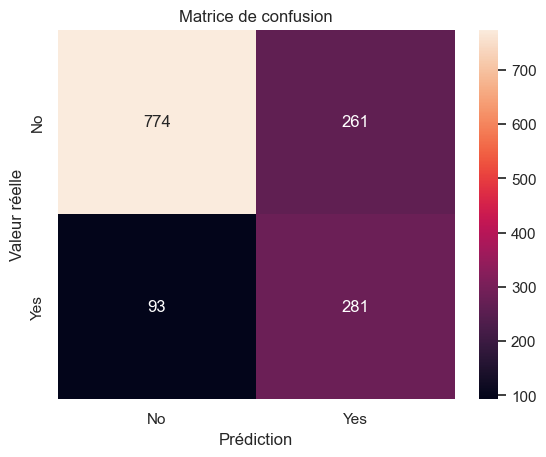

In [ ]:
cm = confusion_matrix(y_test, y_pred_final)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Prédiction")
plt.ylabel("Valeur réelle")
plt.title("Matrice de confusion")
plt.show()

### 13.4 ROC-AUC et PR-AUC

En complément du F1-score, du Recall et de la Precision, nous évaluons également
la capacité du modèle à distinguer les clients susceptibles de churner.

- Le ROC-AUC mesure la capacité globale du modèle à distinguer les deux classes.
- Le PR-AUC (Average Precision) résume le compromis entre Precision et Recall.

La PR-AUC est particulièrement intéressante lorsque la classe positive est
minoritaire, comme dans notre problème de churn.

In [ ]:
# Probabilités de churn sur le jeu de test
y_proba_test = best_logistic.predict_proba(X_test)[:, 1]

# Conversion de la cible en 0/1 pour les métriques basées sur les probabilités
y_test_binary = (y_test == "Yes").astype(int)

# ROC-AUC
roc_auc = roc_auc_score(
    y_test_binary,
    y_proba_test
)

# PR-AUC / Average Precision
pr_auc = average_precision_score(
    y_test_binary,
    y_proba_test
)

print("ROC-AUC :", roc_auc)
print("PR-AUC  :", pr_auc)

ROC-AUC : 0.8412384716732543
PR-AUC  : 0.6281355522895387


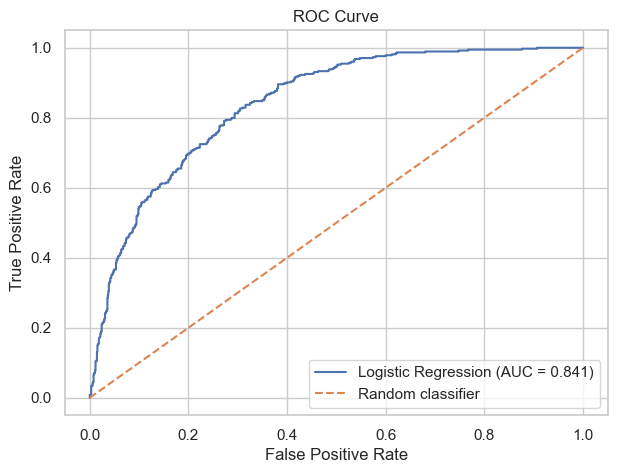

In [ ]:
fpr, tpr, _ = roc_curve(
    y_test_binary,
    y_proba_test
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.show()

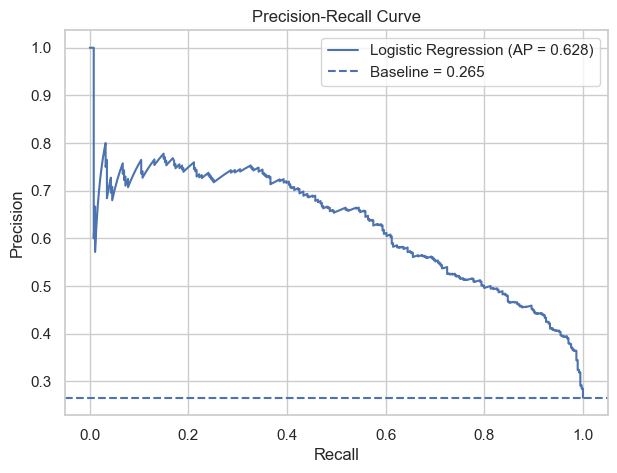

In [ ]:
precision_curve, recall_curve, _ = precision_recall_curve(
    y_test_binary,
    y_proba_test
)

baseline = y_test_binary.mean()

plt.figure(figsize=(7, 5))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"Logistic Regression (AP = {pr_auc:.3f})"
)

plt.axhline(
    y=baseline,
    linestyle="--",
    label=f"Baseline = {baseline:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()

plt.show()

Le modèle obtient un **ROC-AUC de 0.841**, ce qui montre une bonne capacité à distinguer les clients qui churnent de ceux qui restent.

La **PR-AUC de 0.628** est largement supérieure à la baseline de **0.265**, ce qui confirme que le modèle est performant pour détecter la classe minoritaire `Churn = Yes`.

Ces résultats montrent que le modèle fournit de bonnes probabilités de prédiction avant même l'application du seuil de décision.

## 14. Sauvegarde du modèle

In [ ]:
final_model = {
    "model": best_logistic,
    "threshold": best_threshold
}

joblib.dump(final_model, "final_churn_model.joblib")

print("Modèle sauvegardé avec succès.")
print("Seuil sauvegardé :", best_threshold)

Modèle sauvegardé avec succès.
Seuil sauvegardé : 0.30000000000000004


## 14.1 Rechargement du modèle


In [ ]:
loaded_model = joblib.load("final_churn_model.joblib")

loaded_pipeline = loaded_model["model"]
loaded_threshold = loaded_model["threshold"]

print("Modèle rechargé avec succès.")
print("Seuil :", loaded_threshold)

Modèle rechargé avec succès.
Seuil : 0.30000000000000004


Le pipeline complet ainsi que le seuil de décision sont sauvegardés afin de
pouvoir réutiliser le modèle sur de nouveaux clients.

## 15. Prédiction sur un nouveau client

In [ ]:
new_customer = pd.DataFrame({
    "gender": ["Female"],
    "SeniorCitizen": [0],
    "Partner": ["No"],
    "Dependents": ["No"],
    "tenure": [5],
    "PhoneService": ["Yes"],
    "MultipleLines": ["No"],
    "InternetService": ["Fiber optic"],
    "OnlineSecurity": ["No"],
    "OnlineBackup": ["No"],
    "DeviceProtection": ["No"],
    "TechSupport": ["No"],
    "StreamingTV": ["Yes"],
    "StreamingMovies": ["Yes"],
    "Contract": ["Month-to-month"],
    "PaperlessBilling": ["Yes"],
    "PaymentMethod": ["Electronic check"],
    "MonthlyCharges": [85.0],
    "TotalCharges": [425.0]
})

new_customer

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,No,No,5,Yes,No,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,85.0,425.0


In [ ]:
proba = loaded_pipeline.predict_proba(new_customer)

print("P(No churn) :", proba[0][0])
print("P(Yes churn) :", proba[0][1])

proba_churn = proba[0][1]

if proba_churn >= loaded_threshold:
    decision = "Yes"
else:
    decision = "No"

print("P(Churn) :", proba_churn)
print("Seuil :", loaded_threshold)
if decision == "Yes":
    print("➡️ Le modèle estime que ce client présente un risque élevé de churn.")
else:
    print("➡️ Le modèle estime que ce client présente un risque faible de churn.")

P(No churn) : 0.18222729328621556
P(Yes churn) : 0.8177727067137844
P(Churn) : 0.8177727067137844
Seuil : 0.30000000000000004
➡️ Le modèle estime que ce client présente un risque élevé de churn.


Pour simuler une utilisation réelle du modèle, un nouveau client fictif est créé.

Le modèle retourne une probabilité de churn, puis cette probabilité est comparée
au seuil de décision de 0.30.

## 16. Conclusion générale

Ce projet a permis de construire un workflow complet de Machine Learning pour
la prédiction du churn client.

Après comparaison de plusieurs algorithmes par validation croisée, la
**Logistic Regression** a été sélectionnée comme modèle final avec un
F1-score CV d'environ **0.599**.

Le seuil de décision a ensuite été optimisé à **0.30** à partir de prédictions
Out-of-Fold sur les données d'entraînement.

Sur le jeu de test, le modèle obtient :

- Accuracy : **74.9 %**
- Precision : **51.8 %**
- Recall : **75.1 %**
- F1-score : **61.4 %**
- ROC-AUC : **0.841**
- PR-AUC : **0.628**

Le seuil de 0.30 permet de détecter environ trois clients churners sur quatre,
au prix d'une augmentation des faux positifs.

Le projet met ainsi en évidence l'importance de la validation croisée,
de l'interprétation du modèle et de l'adaptation du seuil de classification
aux objectifs métier.